# Random skewers: sf_neutral, the 7/8 bug and the HCD/Forest split

Many sightlines at random positions of the box (no halo centring), extracted with:

| Config | Build | `filter_mode` | star-forming gas |
|---|---|---|---|
| `upstream` | original v2.2.4 | (none) | set neutral (`sf_neutral=True`, default) |
| `upstream_sf0` | original v2.2.4 | (none) | snapshot value (`sf_neutral=False`) |
| `fork_full` | fork | `"None"` | set neutral (`sf_neutral=True`, default) |
| `fork_HCD` | fork | `"HCD_only"` | set neutral (`sf_neutral=True`, default) |
| `fork_Forest` | fork | `"Forest_only"` | set neutral (`sf_neutral=True`, default) |

Each pair isolates one effect:
* `upstream` vs `upstream_sf0` -> **sf_neutral** only (same code).
* `upstream` vs `fork_full` -> **7/8 tau bug** only (same neutral fraction).
* `fork_HCD` + `fork_Forest` vs `fork_full` -> the **decomposition**.

TNG docs on `NeutralHydrogenAbundance`: *"Use with caution for star-forming gas, as the
calculation is based on the 'effective' temperature of the equation of state, which is
not a physical temperature."*

In [1]:
import os
import sys
import json
import subprocess
from pathlib import Path

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib widget
%load_ext autoreload
%autoreload 2

# Same plotting style as the other notebooks (smaller fonts, smaller figures here)
plt.rc('font', family='serif', size=12)
plt.rcParams.update({
    "mathtext.fontset": "cm",
    "axes.linewidth": 1.5,
    "xtick.direction": "in", "ytick.direction": "in",
    "xtick.top": True, "ytick.right": True,
})

In [2]:
# ==============================================================================
# CELL 1: CONFIGURATION
# ==============================================================================
# Project root = the folder that contains tools/
PROJ_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "tools").is_dir())
BENCH_DIR = PROJ_ROOT / "benchmarks"

# --- simulation ---------------------------------------------------------------
SIM_NAME  = "TNG50-2"
BASE_PATH = f"/home/STORAGE/{SIM_NAME}"
SNAP_NUM  = 25                      # z ~ 3.01

# --- random skewers -----------------------------------------------------------
SEED       = 1
N_SKEWERS  = 500     # random lines rarely cross a DLA: keep this in the hundreds
RES_KMS    = 10.0    # pixel width, as in the production runs

# --- the two builds -------------------------------------------------------------
UPSTREAM_DIR = BENCH_DIR / "fake_spectra_upstream"     # bash build_upstream.sh
FORK_DIR     = Path.home() / "fake_spectra_fork"

N_THREADS = 8        # OMP_NUM_THREADS, identical for every run
RERUN     = False    # False: reuse the .npz files already in RESULTS_DIR

for d in (UPSTREAM_DIR, FORK_DIR):
    assert (d / "fake_spectra").is_dir(), f"missing build: {d}"

# One results folder per (simulation, seed, number of skewers)
RESULTS_DIR = BENCH_DIR / "results" / f"{SIM_NAME}_random_seed{SEED}_n{N_SKEWERS}"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print("results :", RESULTS_DIR)

results : /home/vroberto/FakeSpectra_DLAs/benchmarks/results/TNG50-2_random_seed1_n500


In [3]:
# ==============================================================================
# CELL 2: RANDOM SIGHTLINES
# ==============================================================================
# Box size from the group catalogue header (ckpc/h)
group_file = Path(BASE_PATH) / f"groups_{SNAP_NUM:03d}" / f"fof_subhalo_tab_{SNAP_NUM:03d}.0.hdf5"
with h5py.File(group_file, "r") as f:
    box_size = float(f["Header"].attrs["BoxSize"])
    redshift = float(f["Header"].attrs["Redshift"])

# Uniform positions in the box and a random axis per line (1 = x, 2 = y, 3 = z).
# The coordinate along the axis is irrelevant: the sightline crosses the whole box.
rng  = np.random.default_rng(SEED)
axis = rng.integers(1, 4, N_SKEWERS)
cofm = rng.uniform(0, box_size, (N_SKEWERS, 3))

SKEWER_FILE = RESULTS_DIR / "skewers.npy"
np.save(SKEWER_FILE, np.column_stack([axis, cofm]))
print(f"{SIM_NAME} snap {SNAP_NUM}: z = {redshift:.3f}, box = {box_size:.0f} ckpc/h, "
      f"{N_SKEWERS} sightlines")

TNG50-2 snap 25: z = 3.008, box = 35000 ckpc/h, 500 sightlines


In [4]:
# ==============================================================================
# CELL 3: CONFIGURATIONS AND RUNS
# ==============================================================================
# name -> (build folder, filter_mode, sf_neutral, label for the plots)
# No halo here, so the fork's HCD window is off (halo_r200=None): every HCD
# along the line is kept, wherever it is.
CONFIGS = {
    "upstream":     (UPSTREAM_DIR, "None",        1, "Original, sf_neutral=True"),
    "upstream_sf0": (UPSTREAM_DIR, "None",        0, "Original, sf_neutral=False"),
    "fork_full":    (FORK_DIR,     "None",        1, "Fork, full"),
    "fork_HCD":     (FORK_DIR,     "HCD_only",    1, "Fork, HCD_only"),
    "fork_Forest":  (FORK_DIR,     "Forest_only", 1, "Fork, Forest_only"),
}

def run_config(name):
    # Extract all sightlines with config `name`; return the path of its .npz
    impl_dir, mode, sf_neutral, _ = CONFIGS[name]
    out = RESULTS_DIR / f"{name}.npz"
    if out.exists() and not RERUN:
        return out
    cmd = [sys.executable, str(BENCH_DIR / "extract_skewers.py"),
           "--impl_dir", str(impl_dir), "--base", BASE_PATH, "--snap", str(SNAP_NUM),
           "--skewers", str(SKEWER_FILE), "--mode", mode,
           "--res", str(RES_KMS), "--sf_neutral", str(sf_neutral), "--out", str(out)]
    env = dict(os.environ, OMP_NUM_THREADS=str(N_THREADS))
    res = subprocess.run(cmd, capture_output=True, text=True, env=env)
    if res.returncode != 0:
        print(res.stderr[-3000:])
        raise RuntimeError(f"{name} failed")
    print(f"{name:13s}: {json.loads(res.stdout.splitlines()[-1])['total']:8.1f} s")
    return out

for name in CONFIGS:
    run_config(name)

upstream     :    204.2 s
upstream_sf0 :    181.4 s
fork_full    :    174.3 s
fork_HCD     :    105.1 s
fork_Forest  :    161.4 s


In [5]:
# ==============================================================================
# CELL 4: LOAD RESULTS
# ==============================================================================
spec = {name: dict(np.load(RESULTS_DIR / f"{name}.npz")) for name in CONFIGS}

# Sanity check: each config loaded the build it was meant to
for name, d in spec.items():
    print(f"{name:13s} <- {d['loaded_from']}")

tau    = {k: d["tau"]    for k, d in spec.items()}     # (N_SKEWERS, nbins)
colden = {k: d["colden"] for k, d in spec.items()}     # cm^-2 per pixel
flux   = {k: np.exp(-t)  for k, t in tau.items()}

# Integrated column of each sightline (whole box), log10 cm^-2 (+1 avoids log 0)
logN = {k: np.log10(c.sum(axis=1) + 1) for k, c in colden.items()}

# Velocity axis of the box, with v = 0 in the middle pixel
nbins = int(spec["fork_full"]["nbins"])
dv = float(spec["fork_full"]["vmax"]) / nbins
v = (np.arange(nbins) - nbins // 2) * dv

def centred(arr, i_peak):
    # Roll a periodic spectrum so that pixel i_peak sits at v = 0
    return np.roll(arr, nbins // 2 - i_peak)

# Timing of each config (whole table of sightlines)
pd.DataFrame({k: json.loads(str(d["timings"])) for k, d in spec.items()}).T.round(1)

upstream      <- /home/vroberto/FakeSpectra_DLAs/benchmarks/fake_spectra_upstream/fake_spectra/__init__.py
upstream_sf0  <- /home/vroberto/FakeSpectra_DLAs/benchmarks/fake_spectra_upstream/fake_spectra/__init__.py
fork_full     <- /home/vroberto/fake_spectra_fork/fake_spectra/__init__.py
fork_HCD      <- /home/vroberto/fake_spectra_fork/fake_spectra/__init__.py
fork_Forest   <- /home/vroberto/fake_spectra_fork/fake_spectra/__init__.py


,init,tau,colden,total
upstream,0.0,115.3,88.9,204.2
upstream_sf0,0.0,106.6,74.8,181.4
fork_full,0.0,122.2,52.1,174.3
fork_HCD,0.0,105.1,0.0,105.1
fork_Forest,0.0,160.9,0.4,161.4


## 1. sf_neutral (same code, only the neutral fraction of star-forming gas changes)

max |logN fork - logN original| = 1.8e-13
sightlines changed by > 0.01 dex: 2 of 500
LLS+      (log N >= 17.2):  sf_neutral=True   70   False   70
sub-DLA+  (log N >= 19.0):  sf_neutral=True   23   False   23
DLA       (log N >= 20.3):  sf_neutral=True    4   False    3


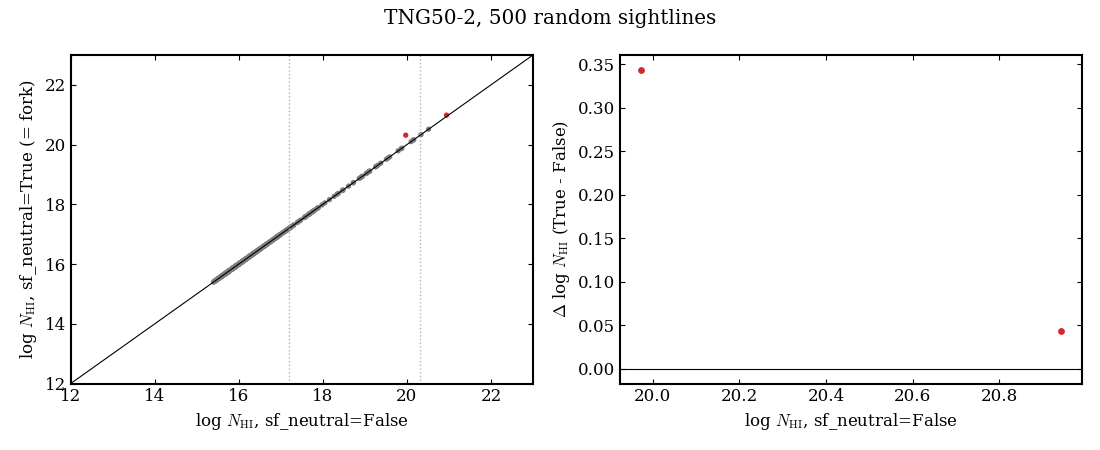

In [6]:
# ==============================================================================
# CELL 5: EFFECT OF sf_neutral ON THE COLUMN DENSITY
# ==============================================================================
# The fork must match the original exactly (same sf_neutral; colden has no 7/8 bug)
print(f"max |logN fork - logN original| = {np.abs(logN['fork_full'] - logN['upstream']).max():.1e}")

dlogN = logN["upstream"] - logN["upstream_sf0"]        # >0 where the correction adds HI
changed = dlogN > 0.01
print(f"sightlines changed by > 0.01 dex: {changed.sum()} of {N_SKEWERS}")

# How many absorbers of each class, with and without the correction
for name, lo in [("LLS+", 17.2), ("sub-DLA+", 19.0), ("DLA", 20.3)]:
    print(f"{name:9s} (log N >= {lo}):  sf_neutral=True {np.sum(logN['upstream'] >= lo):4d}   "
          f"False {np.sum(logN['upstream_sf0'] >= lo):4d}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))

# (a) sightline by sightline: corrected vs snapshot neutral fraction
ax[0].scatter(logN["upstream_sf0"], logN["upstream"], s=8, c=np.where(changed, "C3", "0.5"))
lim = [12, max(23, logN["upstream"].max() + 0.2)]
ax[0].plot(lim, lim, "k-", lw=0.8)
for lo in (17.2, 20.3):
    ax[0].axvline(lo, color="0.7", ls=":", lw=1)
ax[0].set_xlim(lim); ax[0].set_ylim(lim)
ax[0].set_xlabel(r"log $N_{\rm HI}$, sf_neutral=False")
ax[0].set_ylabel(r"log $N_{\rm HI}$, sf_neutral=True (= fork)")

# (b) the size of the correction against the column it acts on
ax[1].scatter(logN["upstream_sf0"][changed], dlogN[changed], s=15, color="C3")
ax[1].axhline(0, color="k", lw=0.8)
ax[1].set_xlabel(r"log $N_{\rm HI}$, sf_neutral=False")
ax[1].set_ylabel(r"$\Delta$ log $N_{\rm HI}$ (True - False)")

fig.suptitle(f"{SIM_NAME}, {N_SKEWERS} random sightlines")
fig.tight_layout()

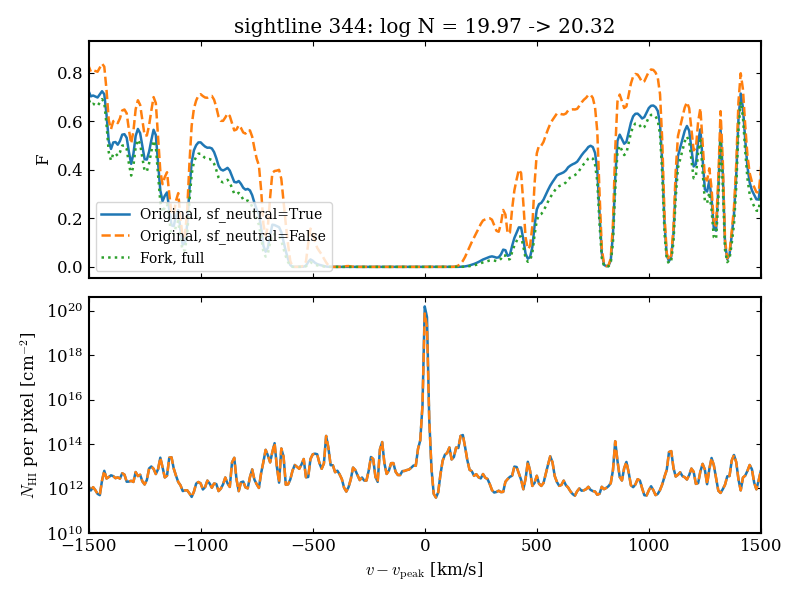

In [7]:
# ==============================================================================
# CELL 6: THE MOST AFFECTED SIGHTLINE
# ==============================================================================
i = int(np.argmax(dlogN))
V_WINDOW = 1500.0                                     # km/s shown around the deepest pixel
i_peak = int(np.argmax(colden["upstream"][i]))

fig, ax = plt.subplots(2, 1, figsize=(8, 6), sharex=True)

# (a) flux: the correction widens the damping wings
for name, ls in [("upstream", "-"), ("upstream_sf0", "--"), ("fork_full", ":")]:
    ax[0].plot(v, centred(flux[name][i], i_peak), ls=ls, lw=1.8, label=CONFIGS[name][3])
ax[0].set_ylabel("F")
ax[0].legend(fontsize=10, loc="lower left")

# (b) column density per pixel: where the extra HI sits
for name, ls in [("upstream", "-"), ("upstream_sf0", "--")]:
    ax[1].semilogy(v, centred(colden[name][i], i_peak), ls=ls, lw=1.8)
ax[1].set_ylim(1e10, None)
ax[1].set_ylabel(r"$N_{\rm HI}$ per pixel [cm$^{-2}$]")
ax[1].set_xlabel(r"$v - v_{\rm peak}$ [km/s]")

ax[0].set_xlim(-V_WINDOW, V_WINDOW)
ax[0].set_title(f"sightline {i}: log N = {logN['upstream_sf0'][i]:.2f} -> {logN['upstream'][i]:.2f}")
fig.tight_layout()

## 2. The 7/8 tau bug (same neutral fraction, only the tau quadrature changes)
The ratio is exactly 7/8 only where the line profile is flat across a cell, so expect a spread around it.

tau original / fork: median 0.8748, 1-99% [0.8663, 0.8784]  (7/8 = 0.875)
<F> Fork, full                   = 0.5410
<F> Original, sf_neutral=False   = 0.5642
<F> Original, sf_neutral=True    = 0.5640


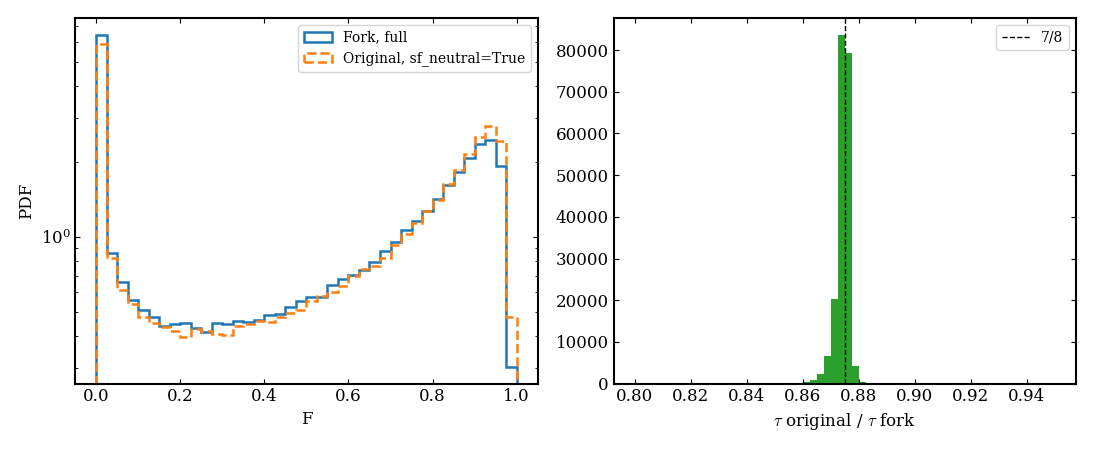

In [8]:
# ==============================================================================
# CELL 7: EFFECT OF THE 7/8 BUG ON THE FLUX
# ==============================================================================
good = tau["fork_full"] > 1e-6                     # skip pixels with no absorption
ratio = tau["upstream"][good] / tau["fork_full"][good]
print(f"tau original / fork: median {np.median(ratio):.4f}, "
      f"1-99% [{np.percentile(ratio, 1):.4f}, {np.percentile(ratio, 99):.4f}]  (7/8 = 0.875)")

# Mean transmitted flux: the forest observable most sensitive to a global tau factor
for name in ("fork_full", "upstream_sf0", "upstream"):
    print(f"<F> {CONFIGS[name][3]:28s} = {flux[name].mean():.4f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))

# (a) flux PDF over all pixels
bins = np.linspace(0, 1, 41)
for name, ls in [("fork_full", "-"), ("upstream", "--")]:
    ax[0].hist(flux[name].ravel(), bins=bins, histtype="step", ls=ls, lw=1.8,
               density=True, label=CONFIGS[name][3])
ax[0].set_yscale("log")
ax[0].set_xlabel("F")
ax[0].set_ylabel("PDF")
ax[0].legend(fontsize=10)

# (b) pixel by pixel tau ratio
ax[1].hist(ratio, bins=np.linspace(0.8, 0.95, 61), color="C2")
ax[1].axvline(7 / 8, color="k", ls="--", lw=1, label="7/8")
ax[1].set_xlabel(r"$\tau$ original / $\tau$ fork")
ax[1].legend(fontsize=10)

fig.tight_layout()

## 3. HCD + Forest = full (fork, no halo window)

max |tau_HCD + tau_Forest - tau_full| / max tau_full = 1.7e-08
sightlines with an HCD (log N_HCD >= 17.2): 64 of 500


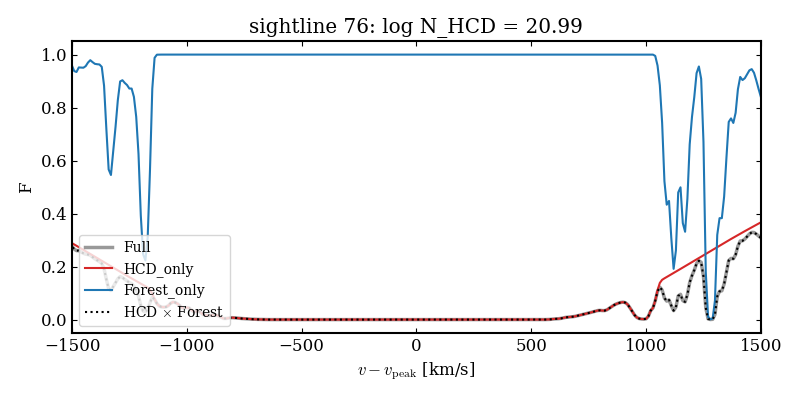

In [9]:
# ==============================================================================
# CELL 8: DECOMPOSITION CHECK
# ==============================================================================
# tau is additive over cells: tau_HCD + tau_Forest must equal tau_full
resid_tau = np.abs(tau["fork_HCD"] + tau["fork_Forest"] - tau["fork_full"])
print(f"max |tau_HCD + tau_Forest - tau_full| / max tau_full = "
      f"{resid_tau.max() / tau['fork_full'].max():.1e}")
print(f"sightlines with an HCD (log N_HCD >= 17.2): {np.sum(logN['fork_HCD'] >= 17.2)} of {N_SKEWERS}")

# Example: the sightline with the strongest HCD
i = int(np.argmax(logN["fork_HCD"]))
i_peak = int(np.argmax(colden["fork_HCD"][i]))
F = {k: centred(flux[k][i], i_peak) for k in ("fork_full", "fork_HCD", "fork_Forest")}

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(v, F["fork_full"], color="k", lw=2.5, alpha=0.4, label="Full")
ax.plot(v, F["fork_HCD"], color="C3", lw=1.5, label="HCD_only")
ax.plot(v, F["fork_Forest"], color="C0", lw=1.5, label="Forest_only")
ax.plot(v, F["fork_HCD"] * F["fork_Forest"], "k:", lw=1.5,
        label=r"HCD $\times$ Forest")
ax.set_xlim(-V_WINDOW, V_WINDOW)
ax.set_xlabel(r"$v - v_{\rm peak}$ [km/s]")
ax.set_ylabel("F")
ax.set_title(f"sightline {i}: log N_HCD = {logN['fork_HCD'][i]:.2f}")
ax.legend(fontsize=10, loc="lower left")
fig.tight_layout()